In [1]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import os



# Black-box evaluation of SAE-augmented models

Our white-box experiments show that the reconstruction error introduced by the sparse autoencoder (SAE) substantially interferes with GCG/BEAST attacks against SAE-augmented models. Here we test whether the effect persists in **black-box** scenarios, where the attacker has no access to internal representations.

We build a unified evaluation set of **1,500 attack prompts** — 500 from each of three public datasets that cover diverse jailbreak and prompt-injection patterns:

* `OpenSafetyLab/Salad-Data` (`attack_enhanced_set`, train split),
* `qualifire/prompt-injections-benchmark` (test split),
* `dynamoai/safe_eval` (train split).

For every model we measure the **attack success rate (ASR)** of (i) the **baseline** model and (ii) the model with the **SAE** inserted into the residual stream.

## ASR evaluation protocols

To reduce detector-specific bias, ASR is measured with **three independent safety judges**:

1. **WildGuard** (`allenai/wildguard`) — a learned classifier that labels responses as safe or harmful; an attack succeeds if the response is labelled harmful.
2. **HarmBench classifier** (`cais/HarmBench-Llama-2-13b-cls`) — same success criterion.
3. **Refusal detector** — a rule-based heuristic that looks for refusal phrases; an attack succeeds if no refusal is detected.

## Generation settings

Generation uses **temperature 0** (greedy decoding), so runs are deterministic. To prevent premature termination via the EOS token — common for jailbreak-style prompts — a single whitespace character (`" "`) is appended to every input prompt for Llama and Mistral. Gemma-2 is trained to emit EOS differently and does not terminate early on these prompts, so its prompts are used unchanged.

## Results

- The SAE does not reduce refusal-based ASR (it may slightly increase it), but the difference is within the confidence intervals.
- The SAE consistently reduces ASR under the HarmBench judge, for both the mean and the median.
- Under WildGuard the effect is small and within the confidence intervals — no strong evidence of a systematic change.

The effect of the SAE is therefore **judge-dependent**: different detectors operationalise "safe" behaviour differently, so safety conclusions do not transfer uniformly across evaluation protocols.

| Mean ASR | 95% CI (mean) | Median ASR | 95% CI (median) | detector_type | experiment_version |
|---:|:---:|---:|:---:|:---:|:---:|
| 0.952 | [0.916, 0.987] | 0.988 | [0.913, 0.997] | refusal | baseline |
| 0.963 | [0.936, 0.990] | 0.986 | [0.935, 0.997] | refusal | SAE |
| 0.215 | [0.141, 0.288] | 0.200 | [0.126, 0.332] | harmbench | baseline |
| 0.132 | [0.064, 0.199] | 0.104 | [0.041, 0.143] | harmbench | SAE |
| 0.447 | [0.367, 0.528] | 0.444 | [0.372, 0.547] | wildguard | baseline |
| 0.421 | [0.336, 0.505] | 0.400 | [0.319, 0.491] | wildguard | SAE |

In [ ]:
from pathlib import Path

ROOT = Path("../results/blackbox_asr")
sorted(p.name for p in ROOT.iterdir() if p.is_dir())

In [ ]:
# Per-prompt judge verdicts live in <model>/<judge>/<baseline|sae>_<dataset>_detailed.jsonl
sorted(str(p.relative_to(ROOT)) for p in (ROOT / "gemma-9b").glob("*/*_detailed.jsonl"))

In [ ]:
# Both tables are produced by scripts/blackbox/aggregate_asr.py
by_file = pd.read_csv(ROOT / "asr_by_file.csv")
summary = pd.read_csv(ROOT / "asr_summary.csv")
summary

Confidence intervals:

- difference between two proportions: https://www.statology.org/confidence-interval-difference-in-proportions/
- single proportion: https://en.wikipedia.org/wiki/Binomial_proportion_confidence_interval
- Wilson interval (preferred): https://www.statisticshowto.com/wilson-ci/

In [5]:
from scipy.stats import mstats
from scipy.stats import t, sem
import numpy as np

for judge in ['refusal', 'harmbench', 'wildguard']:
    for exp_version in ['baseline', 'SAE']: 
        
        data = summary[(summary['judge'] == judge) & (summary['exp_version'] == exp_version)]['ASR'].values
        n = len(data)

        # Calculate the 95% confidence interval for the median (alpha=0.05)
        confidence_interval_median = mstats.median_cihs(data, alpha=0.05)   

        #  sample mean 
        sample_mean = np.mean(data)
        # standard error of the mean
        se = sem(data)  

        confidence_interval_mean = t.interval(
                                            0.95,
                                            df=n-1,
                                            loc=sample_mean,
                                            scale=se
                                        )

        print(f'JUDGE: {judge}, EXP: {exp_version}')
        print(f"Data median: {np.median(data)}")
        print(f"95% Confidence Interval (Hettmasperger-Sheather): {confidence_interval_median}")
        print(f"Data mean: {sample_mean}")
        print(f"95% Confidence Interval for mean: {confidence_interval_mean}")
        print('-'*100)


JUDGE: refusal, EXP: baseline
Data median: 0.992
95% Confidence Interval (Hettmasperger-Sheather): (0.9391797572704373, 1.0)
Data mean: 0.9598888888888888
95% Confidence Interval for mean: (0.929622768273554, 0.9901550095042236)
----------------------------------------------------------------------------------------------------
JUDGE: refusal, EXP: SAE
Data median: 0.987
95% Confidence Interval (Hettmasperger-Sheather): (0.974, 1.0)
Data mean: 0.9692222222222223
95% Confidence Interval for mean: (0.9463148337339767, 0.9921296107104679)
----------------------------------------------------------------------------------------------------
JUDGE: harmbench, EXP: baseline
Data median: 0.20500000000000002
95% Confidence Interval (Hettmasperger-Sheather): (0.13325166017861234, 0.35067643691321276)
Data mean: 0.23244444444444445
95% Confidence Interval for mean: (0.1646306077478462, 0.3002582811410427)
---------------------------------------------------------------------------------------------

In [8]:
summary[summary['judge'] == 'refusal'].groupby(['exp_version'])['ASR'].agg(['mean', 'median', 'min', 'max', 'count'])


,mean,median,min,max,count
exp_version,,,,,
SAE,0.969222,0.987,0.848,1.0,18
baseline,0.959889,0.992,0.788,1.0,18


In [9]:
summary[summary['judge'] != 'refusal'].groupby(['exp_version'])['ASR'].agg(['mean', 'median', 'min', 'max', 'count'])

,mean,median,min,max,count
exp_version,,,,,
SAE,0.286889,0.320,0.002,0.762,36
baseline,0.340222,0.364,0.014,0.676,36


In [10]:
summary[summary['judge'] == 'harmbench'].groupby(['exp_version'])['ASR'].agg(['mean', 'median', 'min', 'max', 'count'])

,mean,median,min,max,count
exp_version,,,,,
SAE,0.159667,0.116,0.002,0.382,18
baseline,0.232444,0.205,0.014,0.472,18


In [12]:
summary[summary['judge'] == 'wildguard'].groupby(['exp_version'])['ASR'].agg(['mean', 'median', 'min', 'max', 'count'])

,mean,median,min,max,count
exp_version,,,,,
SAE,0.414111,0.405,0.164,0.762,18
baseline,0.448000,0.440,0.178,0.676,18


In [14]:
summary.groupby(['exp_version'])['ASR'].agg(['mean', 'median', 'min', 'max', 'count'])

,mean,median,min,max,count
exp_version,,,,,
SAE,0.514333,0.405,0.002,1.0,54
baseline,0.546778,0.445,0.014,1.0,54


Text(0.5, 1.0, 'ASR across models on black box attacks (only refusal detector)')

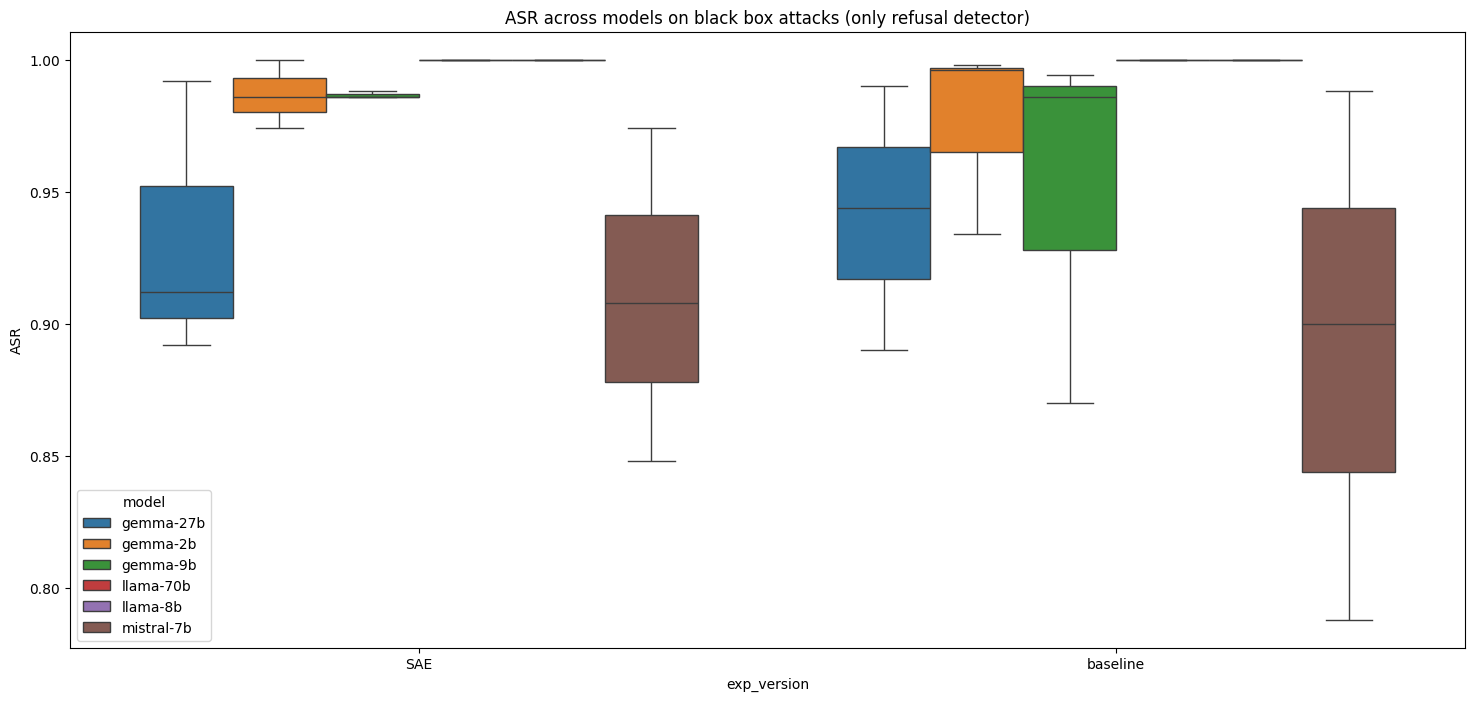

In [15]:
import seaborn as sns

fig, ax = plt.subplots(1, 1, figsize=(18, 8))
sns.boxplot(data=summary[summary['judge'] == 'refusal'], y='ASR', x='exp_version', hue='model')

plt.title('ASR across models on black box attacks (only refusal detector)')

Text(0.5, 1.0, 'ASR across models on black box attacks wildguard and harmbench detectors')

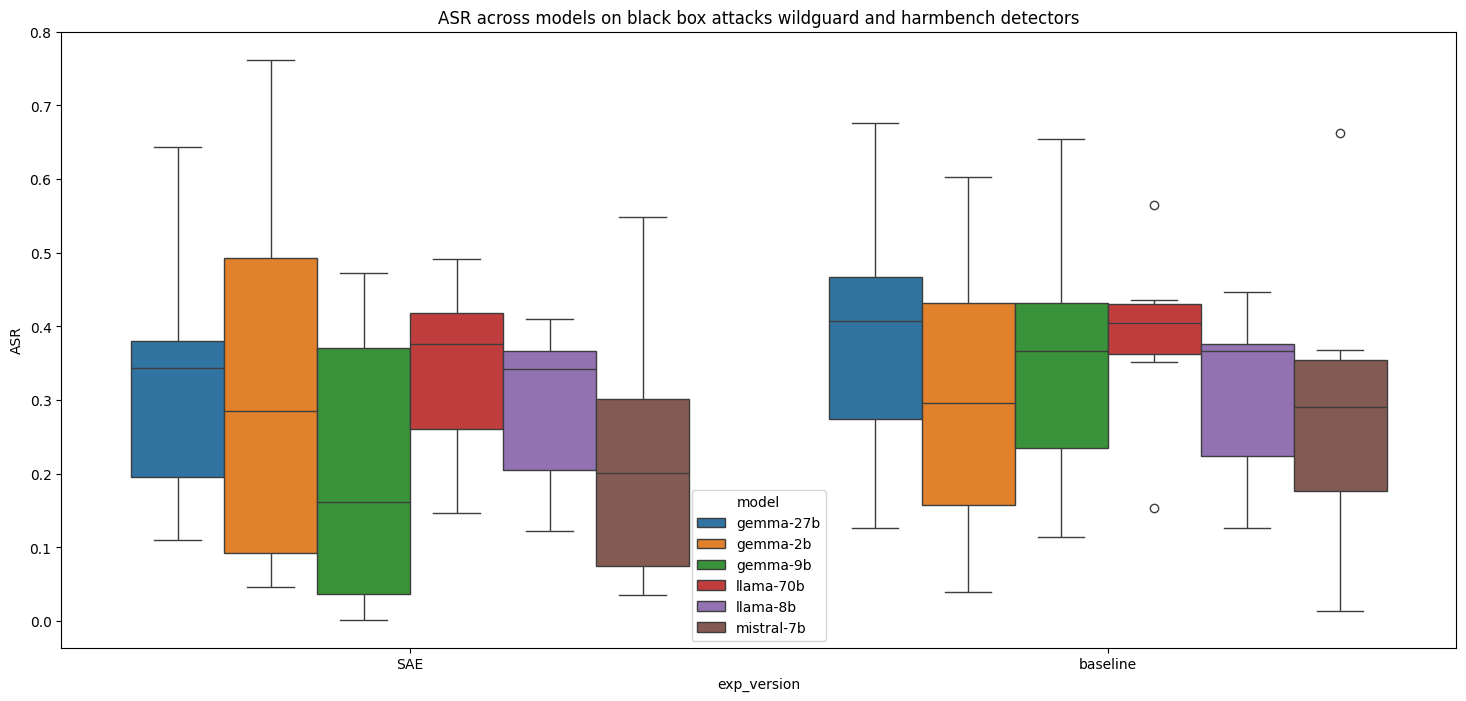

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(18, 8))
sns.boxplot(data=summary[summary['judge'] != 'refusal'], y='ASR', x='exp_version', hue='model')

plt.title('ASR across models on black box attacks wildguard and harmbench detectors')

Text(0.5, 1.0, 'ASR across models on black box attacks harmbench only judge')

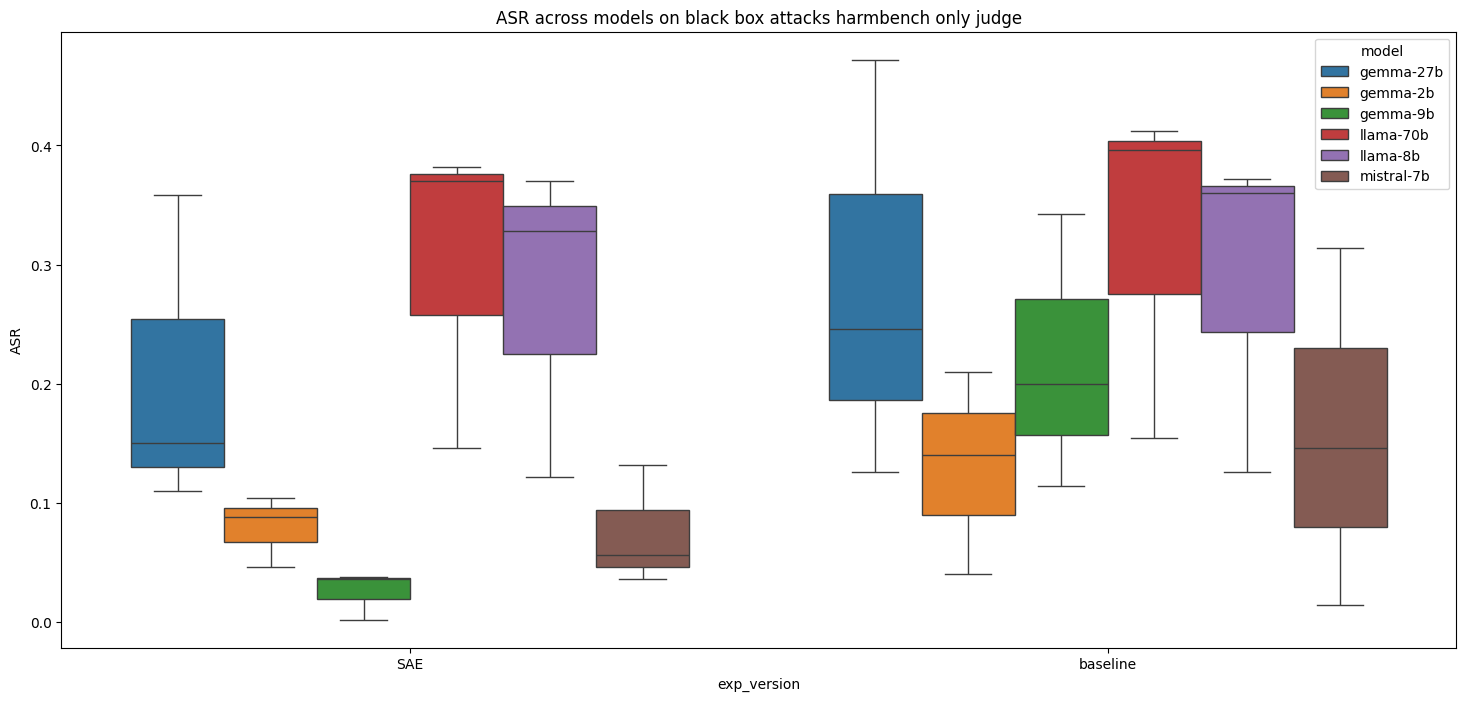

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(18, 8))
sns.boxplot(data=summary[summary['judge'] == 'harmbench'], y='ASR', x='exp_version', hue='model')

plt.title('ASR across models on black box attacks harmbench only judge')

Text(0.5, 1.0, 'ASR across models on black box attacks wildguard only judge')

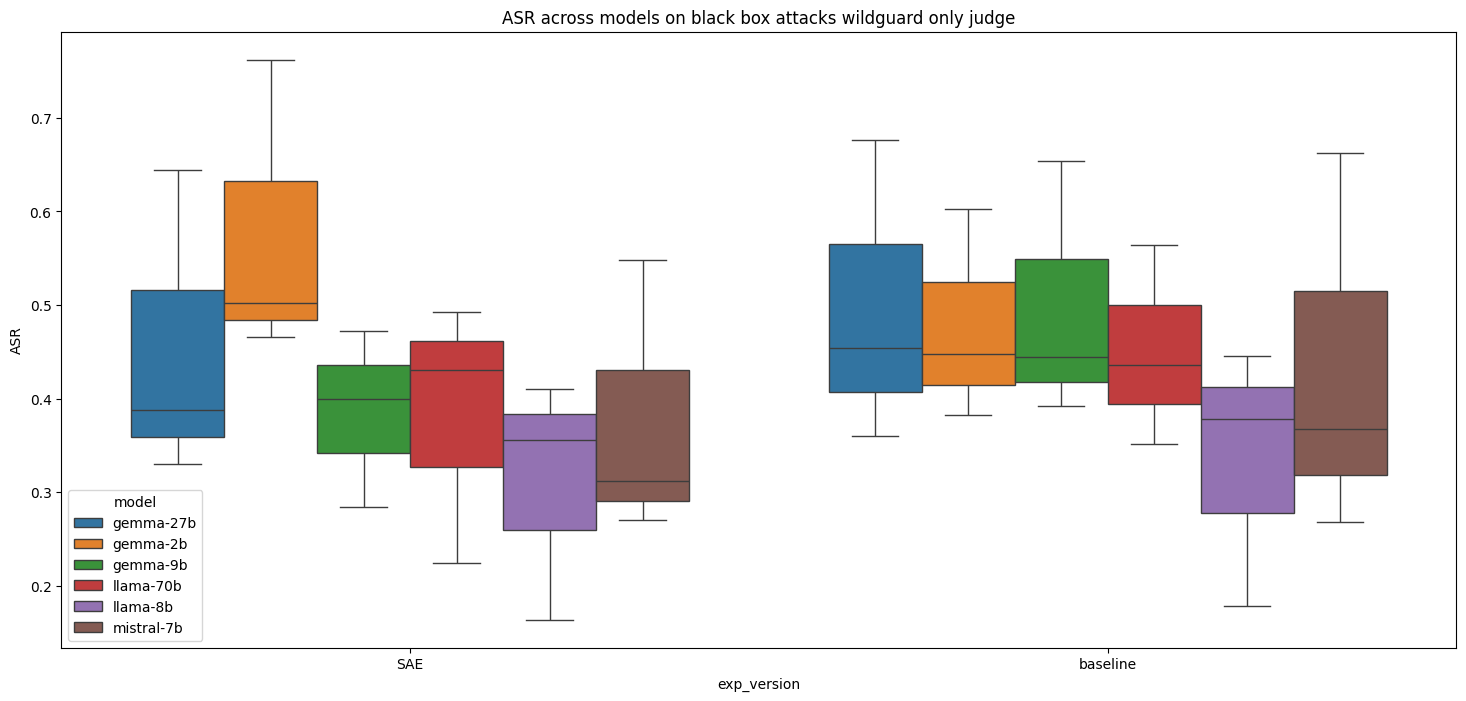

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(18, 8))
sns.boxplot(data=summary[summary['judge'] == 'wildguard'], y='ASR', x='exp_version', hue='model')

plt.title('ASR across models on black box attacks wildguard only judge')